# 1.1 - Análisis y limpieza de datos MiBici

## Objetivo

Analizar la calidad de los registros de viajes de MiBici
correspondientes al periodo enero 2025 - septiembre 2026,
identificando valores nulos, duplicados, inconsistencias
temporales y posibles anomalías.

A partir de los hallazgos, definir reglas de limpieza
justificadas que permitan preparar los datos para las
siguientes etapas del proyecto de Machine Learning.

## Alcance

- Revisar los 21 archivos mensuales.
- Identificar problemas de calidad de datos.
- Evaluar el impacto de las reglas de limpieza.
- Documentar las decisiones tomadas.
- Preparar la implementación de funciones reutilizables.

In [1]:
from pathlib import Path
import pandas as pd

# Carpeta raíz del proyecto
PROJECT_DIR = Path.cwd()

# Si ejecutamos desde notebooks/, subir un nivel
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw" / "viajes"

archivos = sorted(DATA_DIR.glob("datos_abiertos_*.csv"))

print(f"Archivos encontrados: {len(archivos)}")
print(f"Primer archivo: {archivos[0].name}")
print(f"Último archivo: {archivos[-1].name}")

Archivos encontrados: 21
Primer archivo: datos_abiertos_2025_01.csv
Último archivo: datos_abiertos_2026_09.csv


In [2]:
# Revisar estructura y tipos de datos de cada archivo
resumen_estructura = []

for archivo in archivos:
    # Leer únicamente las primeras 100 filas
    try:
        df_muestra = pd.read_csv(
            archivo,
            nrows=100,
            encoding="utf-8"
        )
        encoding = "utf-8"

    except UnicodeDecodeError:
        df_muestra = pd.read_csv(
            archivo,
            nrows=100,
            encoding="latin-1"
        )
        encoding = "latin-1"

    resumen_estructura.append({
        "archivo": archivo.name,
        "columnas": len(df_muestra.columns),
        "encoding": encoding,
        "nombres_columnas": tuple(df_muestra.columns)
    })

df_estructura = pd.DataFrame(resumen_estructura)

display(df_estructura[["archivo", "columnas", "encoding"]])

print("\n¿Todos los archivos tienen las mismas columnas?")
print(df_estructura["nombres_columnas"].nunique() == 1)

print("\nColumnas identificadas:")
print(df_estructura.iloc[0]["nombres_columnas"])

,archivo,columnas,encoding
0,datos_abiertos_2025_01.csv,8,latin-1
1,datos_abiertos_2025_02.csv,8,latin-1
2,datos_abiertos_2025_03.csv,8,utf-8
3,datos_abiertos_2025_04.csv,8,utf-8
4,datos_abiertos_2025_05.csv,8,utf-8
5,datos_abiertos_2025_06.csv,8,utf-8
6,datos_abiertos_2025_07.csv,8,latin-1
7,datos_abiertos_2025_08.csv,8,utf-8
8,datos_abiertos_2025_09.csv,8,utf-8
9,datos_abiertos_2025_10.csv,8,utf-8



¿Todos los archivos tienen las mismas columnas?
True

Columnas identificadas:
('Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id')


In [3]:
# Análisis de calidad de datos por mes

resumen_calidad = []

for archivo in archivos:

    # Identificar encoding
    try:
        df = pd.read_csv(
            archivo,
            encoding="utf-8",
            low_memory=False
        )
    except UnicodeDecodeError:
        df = pd.read_csv(
            archivo,
            encoding="latin-1",
            low_memory=False
        )

    # Convertir fechas
    inicio = pd.to_datetime(
        df["Inicio_del_viaje"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    fin = pd.to_datetime(
        df["Fin_del_viaje"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    # Calcular duración en minutos
    duracion = (fin - inicio).dt.total_seconds() / 60

    resumen_calidad.append({
        "mes": archivo.stem.replace("datos_abiertos_", ""),
        "total_viajes": len(df),
        "duplicados": df.duplicated().sum(),
        "viaje_id_duplicado": df["Viaje_Id"].duplicated().sum(),
        "nulos_totales": df.isna().sum().sum(),
        "fechas_invalidas": (inicio.isna() | fin.isna()).sum(),
        "duracion_negativa": (duracion < 0).sum(),
        "duracion_menor_1min": (
            (duracion >= 0) & (duracion < 1)
        ).sum(),
        "duracion_mayor_3h": (duracion > 180).sum()
    })

    print(f"Analizado: {archivo.name}")

    del df

df_calidad = pd.DataFrame(resumen_calidad)

display(df_calidad)

Analizado: datos_abiertos_2025_01.csv
Analizado: datos_abiertos_2025_02.csv
Analizado: datos_abiertos_2025_03.csv
Analizado: datos_abiertos_2025_04.csv
Analizado: datos_abiertos_2025_05.csv
Analizado: datos_abiertos_2025_06.csv
Analizado: datos_abiertos_2025_07.csv
Analizado: datos_abiertos_2025_08.csv
Analizado: datos_abiertos_2025_09.csv
Analizado: datos_abiertos_2025_10.csv
Analizado: datos_abiertos_2025_11.csv
Analizado: datos_abiertos_2025_12.csv
Analizado: datos_abiertos_2026_01.csv
Analizado: datos_abiertos_2026_02.csv
Analizado: datos_abiertos_2026_03.csv
Analizado: datos_abiertos_2026_04.csv
Analizado: datos_abiertos_2026_05.csv
Analizado: datos_abiertos_2026_06.csv
Analizado: datos_abiertos_2026_07.csv
Analizado: datos_abiertos_2026_08.csv
Analizado: datos_abiertos_2026_09.csv


,mes,total_viajes,duplicados,viaje_id_duplicado,nulos_totales,fechas_invalidas,duracion_negativa,duracion_menor_1min,duracion_mayor_3h
0,2025_01,380184,0,0,2849,0,0,9282,45
1,2025_02,372529,0,0,3115,0,0,9018,42
2,2025_03,405110,0,0,3389,0,0,10351,52
3,2025_04,366193,0,0,3643,0,0,9137,20
4,2025_05,395891,0,0,3802,0,0,10051,32
5,2025_06,356611,0,0,3431,0,0,9726,50
6,2025_07,368186,0,0,3502,0,0,9773,35
7,2025_08,374727,0,0,3477,0,0,10099,33
8,2025_09,376789,0,0,3455,0,0,10190,35
9,2025_10,420064,0,0,4376,0,0,10524,37


In [4]:
# Analizar valores nulos por columna en los 21 meses

resumen_nulos = []

for archivo in archivos:
    try:
        df = pd.read_csv(
            archivo,
            encoding="utf-8",
            low_memory=False
        )
    except UnicodeDecodeError:
        df = pd.read_csv(
            archivo,
            encoding="latin-1",
            low_memory=False
        )

    nulos = df.isna().sum()

    resumen_nulos.append({
        "mes": archivo.stem.replace("datos_abiertos_", ""),
        **nulos.to_dict()
    })

    del df

df_nulos = pd.DataFrame(resumen_nulos).set_index("mes")

display(df_nulos)

print("\nTotal de valores nulos por columna:")
display(df_nulos.sum().sort_values(ascending=False))

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
mes,,,,,,,,
2025_01,0,0,2702,147,0,0,0,0
2025_02,0,0,2982,133,0,0,0,0
2025_03,0,0,3213,176,0,0,0,0
2025_04,0,0,3483,160,0,0,0,0
2025_05,0,0,3706,96,0,0,0,0
2025_06,0,0,3333,98,0,0,0,0
2025_07,0,0,3464,38,0,0,0,0
2025_08,0,0,3452,25,0,0,0,0
2025_09,0,0,3426,29,0,0,0,0



Total de valores nulos por columna:


Genero               62743
Año_de_nacimiento     1436
Viaje_Id                 0
Usuario_Id               0
Inicio_del_viaje         0
Fin_del_viaje            0
Origen_Id                0
Destino_Id               0
dtype: int64

## Tratamiento de valores nulos

Se identificaron valores faltantes en dos columnas:

- Genero: 62,743 valores nulos.
- Año_de_nacimiento: 1,436 valores nulos.

Las columnas restantes no presentan valores nulos.

Dado que el objetivo del proyecto es predecir la demanda de
viajes por estación y hora, las variables demográficas no son
indispensables para construir la variable objetivo.

Por lo tanto, se decidió conservar los registros con valores
faltantes en estas columnas, evitando eliminar viajes válidos
o introducir valores imputados sin justificación.

Las variables de fecha y estación de origen no presentan
valores faltantes.

In [5]:
# Analizar viajes cortos por mes

resumen_cortos = []

for archivo in archivos:

    try:
        df = pd.read_csv(
            archivo,
            encoding="utf-8",
            low_memory=False
        )
    except UnicodeDecodeError:
        df = pd.read_csv(
            archivo,
            encoding="latin-1",
            low_memory=False
        )

    inicio = pd.to_datetime(
        df["Inicio_del_viaje"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    fin = pd.to_datetime(
        df["Fin_del_viaje"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    duracion_seg = (fin - inicio).dt.total_seconds()

    cortos = duracion_seg.between(0, 60, inclusive="left")

    mismo_origen = (
        df["Origen_Id"] == df["Destino_Id"]
    )

    resumen_cortos.append({
        "mes": archivo.stem.replace("datos_abiertos_", ""),
        "viajes_cortos": int(cortos.sum()),
        "cortos_misma_estacion": int(
            (cortos & mismo_origen).sum()
        ),
        "cortos_distinta_estacion": int(
            (cortos & ~mismo_origen).sum()
        ),
        "porcentaje_cortos": round(
            cortos.mean() * 100, 2
        )
    })

    del df

df_cortos = pd.DataFrame(resumen_cortos)

display(df_cortos)

,mes,viajes_cortos,cortos_misma_estacion,cortos_distinta_estacion,porcentaje_cortos
0,2025_01,9282,8787,495,2.44
1,2025_02,9018,8536,482,2.42
2,2025_03,10351,9757,594,2.56
3,2025_04,9137,8720,417,2.50
4,2025_05,10051,9543,508,2.54
5,2025_06,9726,8983,743,2.73
6,2025_07,9773,9239,534,2.65
7,2025_08,10099,9527,572,2.70
8,2025_09,10190,9608,582,2.70
9,2025_10,10524,9996,528,2.51


## Análisis de viajes de corta duración

Se analizaron los viajes con duración inferior a un minuto durante el periodo enero 2025 - septiembre 2026.

* Se observó que la mayoría de estos registros corresponden a viajes cuyo origen y destino son la misma estación.

* Durante 2025, los viajes cortos representaron aproximadamente entre el 2.4% y el 2.7% de los registros mensuales.

* En junio de 2026, este porcentaje aumentó al 4.99%, con 3,437 viajes cortos entre estaciones diferentes.

Estos resultados sugieren posibles anomalías operativas o diferencias en el registro de viajes, pero no permiten confirmar su causa.

Por lo tanto, se propone identificar y marcar estos registros antes de decidir su exclusión del conjunto de datos utilizado para el modelado.

In [6]:
import sys

# Importa módulos desde la raíz del proyecto
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from proyecto_mlops_equipo_9.cleaning import limpiar_viajes

# Probar con septiembre de 2026
ruta = DATA_DIR / "datos_abiertos_2026_09.csv"

df_original = pd.read_csv(
    ruta,
    encoding="utf-8",
    low_memory=False
)

df_limpio = limpiar_viajes(df_original)

print("Registros originales:", len(df_original))
print("Registros después de limpieza:", len(df_limpio))
print("Duplicados eliminados:", len(df_original) - len(df_limpio))

print("\nColumnas resultantes:")
print(df_limpio.columns.tolist())

print("\nRegistros sospechosos:")
print("Viajes cortos:", df_limpio["viaje_corto"].sum())
print(
    "Cortos entre distintas estaciones:",
    df_limpio["corto_distinta_estacion"].sum()
)
print("Duraciones largas:", df_limpio["duracion_larga"].sum())

2026-10-22 22:06:08.518 | INFO     | proyecto_mlops_equipo_9.config:<module>:11 - PROJ_ROOT path is: /Users/arijim/Documents/Proyecto_MLOPS_Equipo_9


Registros originales: 490056
Registros después de limpieza: 489298
Duplicados eliminados: 758

Columnas resultantes:
['viaje_id', 'usuario_id', 'genero', 'anio_nacimiento', 'inicio', 'fin', 'origen_id', 'destino_id', 'duracion_min', 'viaje_corto', 'corto_distinta_estacion', 'duracion_larga']

Registros sospechosos:
Viajes cortos: 18949
Cortos entre distintas estaciones: 1307
Duraciones largas: 37


In [7]:
# Validaciones básicas de nuestra función

assert len(df_original) == 490056
assert len(df_limpio) == 489298

# No deben quedar filas completamente duplicadas
assert df_limpio.duplicated().sum() == 0

# El DataFrame original conserva sus columnas
assert "Inicio_del_viaje" in df_original.columns

# El DataFrame limpio tiene las columnas estandarizadas
assert "inicio" in df_limpio.columns

# Conservamos los valores demográficos faltantes
assert df_limpio["genero"].isna().sum() > 0

print("Todas las validaciones pasaron correctamente.")

Todas las validaciones pasaron correctamente.


In [8]:
resumen_limpieza = []

for archivo in archivos:
    try:
        df_mes = pd.read_csv(
        archivo,
        encoding="utf-8",
        low_memory=False
    )
    except UnicodeDecodeError:
        df_mes = pd.read_csv(
            archivo,
            encoding="latin-1",
            low_memory=False
    )

    df_mes_limpio = limpiar_viajes(df_mes)

    resumen_limpieza.append({
        "mes": archivo.stem.replace("datos_abiertos_", ""),
        "originales": len(df_mes),
        "limpios": len(df_mes_limpio),
        "duplicados_eliminados": len(df_mes) - len(df_mes_limpio),
        "viajes_cortos": int(df_mes_limpio["viaje_corto"].sum()),
        "cortos_distinta_estacion": int(
            df_mes_limpio["corto_distinta_estacion"].sum()
        ),
        "duraciones_largas": int(df_mes_limpio["duracion_larga"].sum())
    })

    del df_mes, df_mes_limpio

resumen_df = pd.DataFrame(resumen_limpieza)

display(resumen_df)

print("\nRESUMEN GENERAL")
print("Meses procesados:", len(resumen_df))
print("Registros originales:", resumen_df["originales"].sum())
print("Registros limpios:", resumen_df["limpios"].sum())
print(
    "Duplicados eliminados:",
    resumen_df["duplicados_eliminados"].sum()
)

,mes,originales,limpios,duplicados_eliminados,viajes_cortos,cortos_distinta_estacion,duraciones_largas
0,2025_01,380184,380184,0,9282,495,45
1,2025_02,372529,372529,0,9018,482,42
2,2025_03,405110,405110,0,10351,594,52
3,2025_04,366193,366193,0,9137,417,20
4,2025_05,395891,395891,0,10051,508,32
5,2025_06,356611,356611,0,9726,743,50
6,2025_07,368186,368186,0,9773,534,35
7,2025_08,374727,374727,0,10099,572,33
8,2025_09,376789,376789,0,10190,582,35
9,2025_10,420064,420064,0,10524,528,37



RESUMEN GENERAL
Meses procesados: 21
Registros originales: 7894097
Registros limpios: 7893339
Duplicados eliminados: 758


## Métricas de calidad de datos

Con el objetivo de evaluar la calidad del conjunto de datos de MiBici, se calcularon indicadores porcentuales para los 21 archivos mensuales correspondientes al periodo enero de 2025 a septiembre de 2026.

Se consideran los siguientes indicadores:

- **Porcentaje de duplicados:** proporción de registros idénticos detectados en cada archivo mensual.
- **Porcentaje de viajes cortos:** proporción de viajes con duración inferior a un minuto.
- **Porcentaje de viajes cortos entre estaciones distintas:** registros de menos de un minuto cuyo origen y destino son diferentes.
- **Porcentaje de viajes largos:** proporción de viajes con duración superior a tres horas.

Estas métricas permiten comparar la calidad de los registros entre meses con diferentes volúmenes de viajes. Los viajes de duración sospechosa se conservan y etiquetan para su análisis posterior.

In [9]:
# Métricas porcentuales de calidad de datos

resumen_df["pct_duplicados"] = (
    resumen_df["duplicados_eliminados"]
    / resumen_df["originales"] * 100
)

resumen_df["pct_viajes_cortos"] = (
    resumen_df["viajes_cortos"]
    / resumen_df["limpios"] * 100
)

resumen_df["pct_cortos_distinta_estacion"] = (
    resumen_df["cortos_distinta_estacion"]
    / resumen_df["limpios"] * 100
)

resumen_df["pct_duraciones_largas"] = (
    resumen_df["duraciones_largas"]
    / resumen_df["limpios"] * 100
)

columnas_metricas = [
    "mes",
    "pct_duplicados",
    "pct_viajes_cortos",
    "pct_cortos_distinta_estacion",
    "pct_duraciones_largas"
]

display(resumen_df[columnas_metricas].round(3))

,mes,pct_duplicados,pct_viajes_cortos,pct_cortos_distinta_estacion,pct_duraciones_largas
0,2025_01,0.000,2.441,0.130,0.012
1,2025_02,0.000,2.421,0.129,0.011
2,2025_03,0.000,2.555,0.147,0.013
3,2025_04,0.000,2.495,0.114,0.005
4,2025_05,0.000,2.539,0.128,0.008
5,2025_06,0.000,2.727,0.208,0.014
6,2025_07,0.000,2.654,0.145,0.010
7,2025_08,0.000,2.695,0.153,0.009
8,2025_09,0.000,2.704,0.154,0.009
9,2025_10,0.000,2.505,0.126,0.009


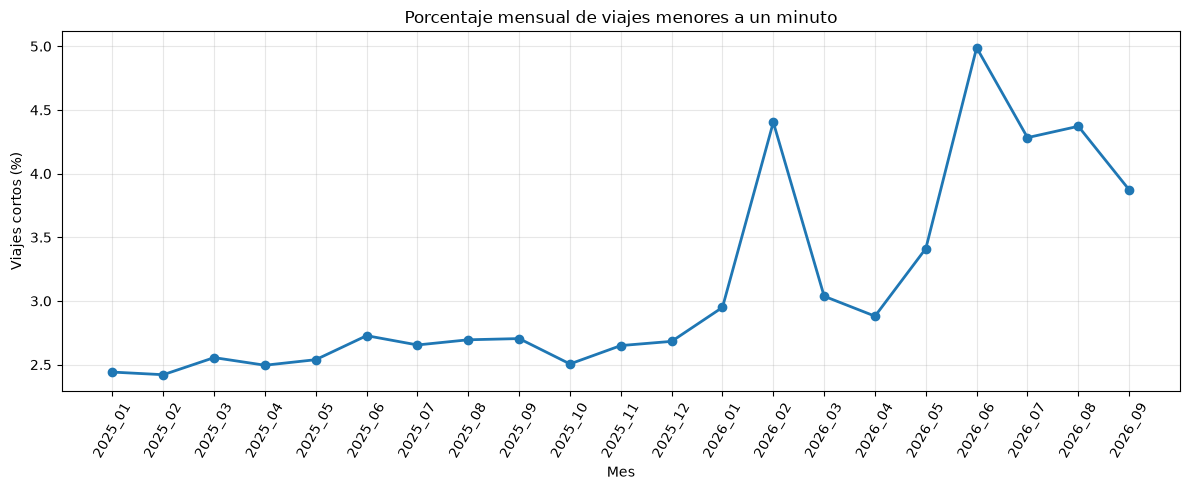

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    resumen_df["mes"],
    resumen_df["pct_viajes_cortos"],
    marker="o",
    linewidth=2
)

plt.title("Porcentaje mensual de viajes menores a un minuto")
plt.xlabel("Mes")
plt.ylabel("Viajes cortos (%)")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de los viajes de corta duración

Durante 2025, la proporción de viajes menores a un minuto se mantuvo relativamente estable, entre 2.4 % y 2.7 % del total mensual.

En 2026 se identificaron incrementos importantes, particularmente en febrero (4.40 %) y junio (4.99 %), siendo este último el valor máximo del periodo analizado. Entre julio y septiembre de 2026, los porcentajes permanecieron por encima de los niveles observados durante 2025.

Este comportamiento podría estar relacionado con cambios operativos, diferencias en el registro de viajes o variaciones en el uso del sistema. Sin embargo, los datos disponibles no permiten establecer una causa definitiva.

**Decisión de limpieza:** se conservarán los viajes menores a un minuto, identificándolos mediante indicadores de calidad. Su posible exclusión deberá evaluarse posteriormente según la definición de demanda y los objetivos del modelo predictivo.

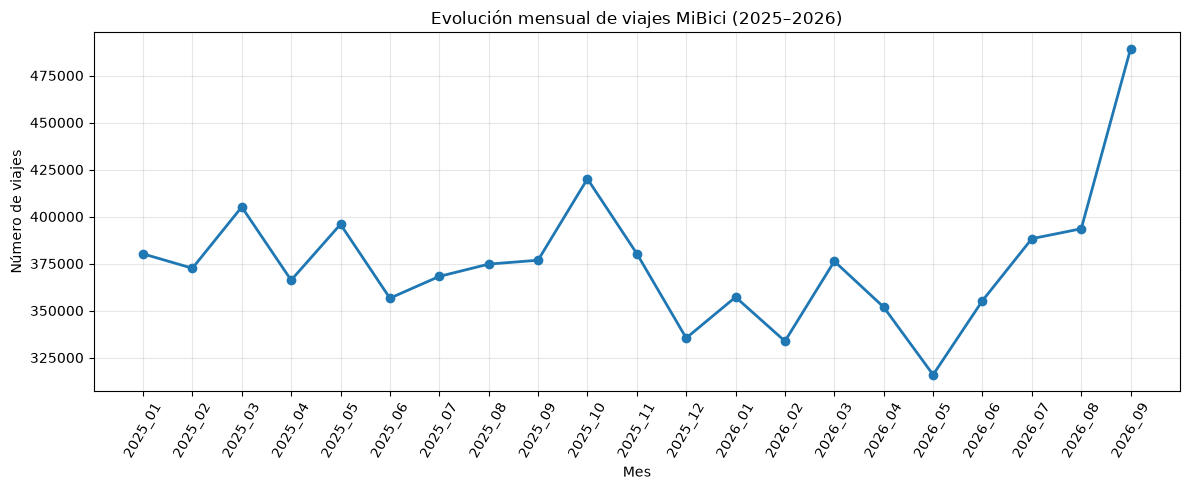

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    resumen_df["mes"],
    resumen_df["limpios"],
    marker="o",
    linewidth=2
)

plt.title("Evolución mensual de viajes MiBici (2025–2026)")
plt.xlabel("Mes")
plt.ylabel("Número de viajes")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de la evolución mensual de viajes

Durante el periodo enero de 2025 a septiembre de 2026, el volumen mensual de viajes de MiBici presentó fluctuaciones importantes.

En 2025, los registros mensuales oscilaron aproximadamente entre 335 mil y 420 mil viajes. En 2026 se observó una disminución progresiva hasta mayo, mes que registró el menor volumen del periodo (315,895 viajes).

Posteriormente, el número de viajes aumentó, alcanzando su valor máximo en septiembre de 2026, con 489,298 registros después de eliminar duplicados exactos.

Estas variaciones podrían estar relacionadas con factores temporales, estacionales o cambios en la cobertura del sistema. Sin embargo, se requiere un análisis adicional para determinar su influencia.

**Implicación para el modelado:** el comportamiento temporal de la demanda debe analizarse considerando la hora, el día de la semana y los cambios en la disponibilidad de estaciones. Asimismo, resulta conveniente utilizar métricas normalizadas, como viajes promedio por día, para comparar periodos de distinta duración.

In [12]:
# Convertir el identificador del mes a fecha
resumen_df["fecha_mes"] = pd.to_datetime(
    resumen_df["mes"],
    format="%Y_%m"
)

# Número de días de cada mes
resumen_df["dias_mes"] = resumen_df["fecha_mes"].dt.days_in_month

# Calcular promedio diario de viajes
resumen_df["promedio_diario"] = (
    resumen_df["limpios"] / resumen_df["dias_mes"]
)

display(
    resumen_df[
        ["mes", "limpios", "dias_mes", "promedio_diario"]
    ].round(2)
)

,mes,limpios,dias_mes,promedio_diario
0,2025_01,380184,31,12264.00
1,2025_02,372529,28,13304.61
2,2025_03,405110,31,13068.06
3,2025_04,366193,30,12206.43
4,2025_05,395891,31,12770.68
5,2025_06,356611,30,11887.03
6,2025_07,368186,31,11876.97
7,2025_08,374727,31,12087.97
8,2025_09,376789,30,12559.63
9,2025_10,420064,31,13550.45


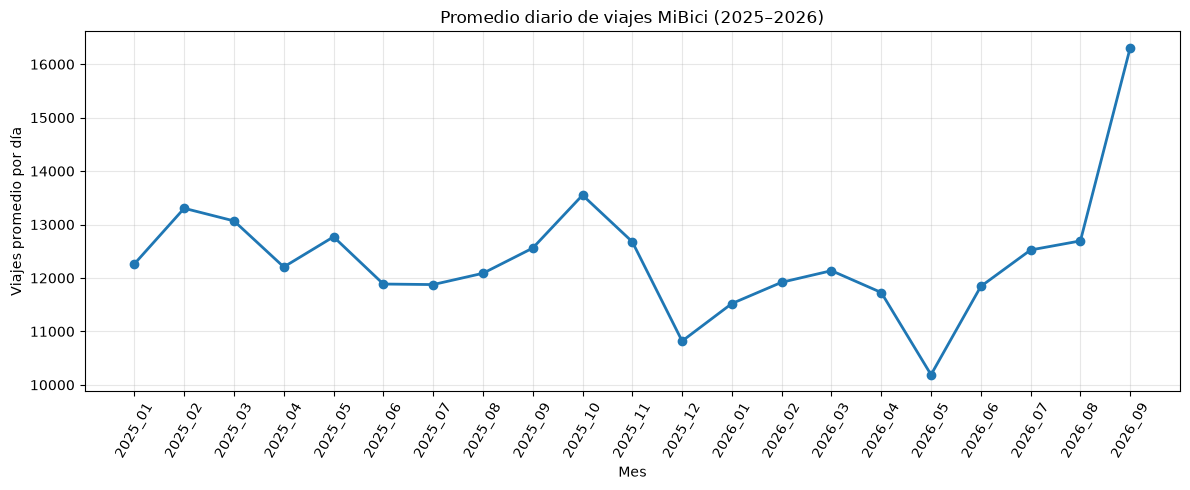

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    resumen_df["mes"],
    resumen_df["promedio_diario"],
    marker="o",
    linewidth=2
)

plt.title("Promedio diario de viajes MiBici (2025–2026)")
plt.xlabel("Mes")
plt.ylabel("Viajes promedio por día")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación del promedio diario de viajes

Para comparar adecuadamente los volúmenes de viajes entre meses de distinta duración, se calculó el promedio diario dividiendo el número de viajes limpios entre los días correspondientes a cada mes.

Durante 2025, el promedio diario presentó fluctuaciones moderadas, generalmente entre 12,000 y 13,500 viajes. En mayo de 2026 se registró el valor más bajo del periodo, con aproximadamente 10,190 viajes diarios.

A partir de junio de 2026 se observó una recuperación, alcanzando en septiembre el máximo del periodo, con aproximadamente 16,310 viajes diarios.

Este incremento persiste después de normalizar por la duración de los meses. No obstante, el indicador todavía no considera las variaciones en el número de estaciones disponibles, por lo que no debe interpretarse directamente como un aumento de demanda por estación.

**Implicación para el modelado:** se recomienda analizar patrones temporales y cambios en la cobertura del sistema antes de definir las variables predictoras y los periodos de evaluación.

In [14]:
# Análisis de patrones temporales de inicio de viajes

conteo_dias = pd.Series(0, index=range(7), dtype="int64")
conteo_horas = pd.Series(0, index=range(24), dtype="int64")

for archivo in archivos:
    try:
        df_mes = pd.read_csv(
            archivo, encoding="utf-8", low_memory=False
        )
    except UnicodeDecodeError:
        df_mes = pd.read_csv(
            archivo, encoding="latin-1", low_memory=False
        )

    df_mes = limpiar_viajes(df_mes)

    # Contar viajes por día de la semana
    dias = df_mes["inicio"].dt.dayofweek.value_counts()
    conteo_dias = conteo_dias.add(dias, fill_value=0)

    # Contar viajes por hora de inicio
    horas = df_mes["inicio"].dt.hour.value_counts()
    conteo_horas = conteo_horas.add(horas, fill_value=0)

    del df_mes

conteo_dias = conteo_dias.astype(int)
conteo_horas = conteo_horas.astype(int)

dias_semana = [
    "Lunes", "Martes", "Miércoles",
    "Jueves", "Viernes", "Sábado", "Domingo"
]

print("Viajes por día de la semana:")
display(pd.DataFrame({
    "dia": dias_semana,
    "viajes": conteo_dias.values
}))

print("\nViajes por hora:")
display(pd.DataFrame({
    "hora": conteo_horas.index,
    "viajes": conteo_horas.values
}))

Viajes por día de la semana:


,dia,viajes
0,Lunes,1188237
1,Martes,1287339
2,Miércoles,1289794
3,Jueves,1244662
4,Viernes,1208688
5,Sábado,886460
6,Domingo,788159



Viajes por hora:


,hora,viajes
0,0,50231
1,1,107
2,2,10
3,3,1
4,4,9
5,5,65727
6,6,226274
7,7,443763
8,8,608221
9,9,437961


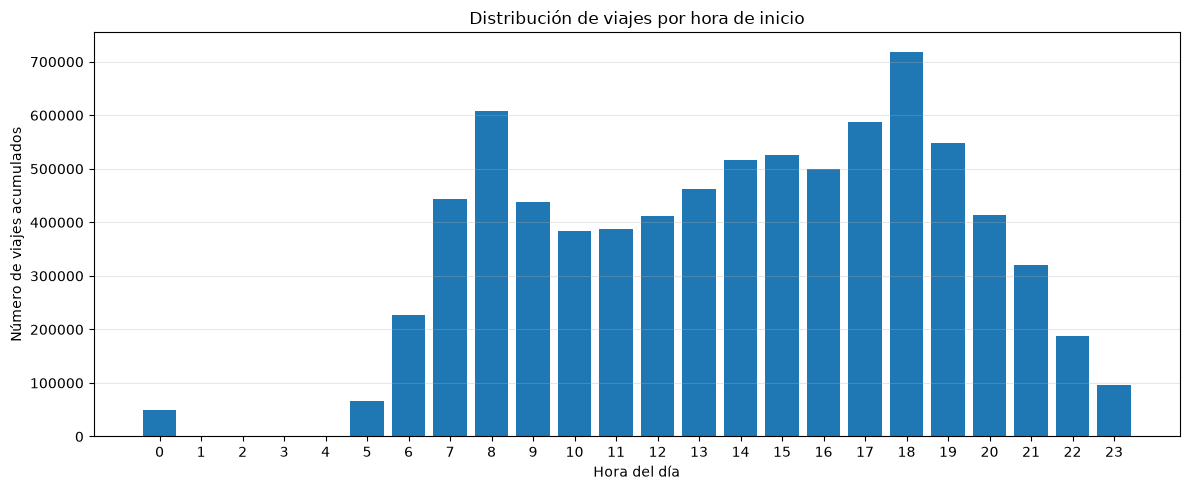

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    conteo_horas.index,
    conteo_horas.values
)

plt.title("Distribución de viajes por hora de inicio")
plt.xlabel("Hora del día")
plt.ylabel("Número de viajes acumulados")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación de la distribución horaria

La distribución de viajes por hora de inicio muestra dos periodos de mayor actividad: uno matutino, alrededor de las 8:00 horas, y otro vespertino, alrededor de las 18:00 horas.

El mayor volumen se registró a las 18:00 horas, con 719,008 viajes acumulados, seguido de las 8:00 horas, con 608,221 viajes.

Estos patrones son compatibles con desplazamientos cotidianos asociados a actividades laborales o académicas, aunque el propósito de cada viaje no puede determinarse directamente a partir del dataset.

También se observa una actividad mínima entre la 1:00 y las 4:59 horas, cuyo origen requiere verificarse antes de establecer conclusiones.

**Implicación para el modelado:** la hora del día podría ser una variable predictora relevante para estimar la demanda. Asimismo, convendría evaluar la interacción entre la hora y el día de la semana para identificar diferencias entre días laborales y fines de semana.

In [16]:
# Calcular cuántas veces aparece cada día de la semana
fecha_inicio = pd.Timestamp("2025-01-01")
fecha_fin = pd.Timestamp("2026-09-30")

fechas = pd.date_range(
    start=fecha_inicio,
    end=fecha_fin,
    freq="D"
)

numero_dias = (
    pd.Series(fechas.dayofweek)
    .value_counts()
    .reindex(range(7), fill_value=0)
)

# Promedio de viajes por cada día de la semana
promedio_por_dia = conteo_dias / numero_dias

resumen_dias = pd.DataFrame({
    "dia": dias_semana,
    "numero_dias": numero_dias.values,
    "viajes_totales": conteo_dias.values,
    "promedio_viajes": promedio_por_dia.values
})

display(resumen_dias.round(2))

,dia,numero_dias,viajes_totales,promedio_viajes
0,Lunes,91,1188237,13057.55
1,Martes,91,1287339,14146.58
2,Miércoles,92,1289794,14019.50
3,Jueves,91,1244662,13677.60
4,Viernes,91,1208688,13282.29
5,Sábado,91,886460,9741.32
6,Domingo,91,788159,8661.09


### Interpretación de la demanda por día de la semana

Se calculó el promedio de viajes por día de la semana considerando el número de veces que cada día aparece durante el periodo enero de 2025 a septiembre de 2026.

Aunque el miércoles presentó el mayor número acumulado de viajes, después de normalizar se identificó que el martes registra el mayor promedio diario, con aproximadamente 14,147 viajes, seguido del miércoles con 14,020.

Los sábados y domingos presentan una actividad considerablemente menor, siendo el domingo el día de menor uso, con aproximadamente 8,661 viajes diarios.

Estos resultados sugieren una diferencia importante entre los patrones de uso de días laborales y fines de semana.

**Implicación para el modelado:** el día de la semana y un indicador de fin de semana podrían ser variables relevantes para la predicción de demanda. Sin embargo, será necesario evaluar su contribución durante el entrenamiento y la validación del modelo.

In [17]:
resumen_estaciones = []

for archivo in archivos:
    try:
        df_mes = pd.read_csv(
            archivo, encoding="utf-8", low_memory=False
        )
    except UnicodeDecodeError:
        df_mes = pd.read_csv(
            archivo, encoding="latin-1", low_memory=False
        )

    df_mes = limpiar_viajes(df_mes)

    resumen_estaciones.append({
        "mes": archivo.stem.replace("datos_abiertos_", ""),
        "estaciones_origen_activas": df_mes["origen_id"].nunique(),
        "viajes": len(df_mes)
    })

    del df_mes

estaciones_df = pd.DataFrame(resumen_estaciones)

estaciones_df["viajes_por_estacion_activa"] = (
    estaciones_df["viajes"]
    / estaciones_df["estaciones_origen_activas"]
)

display(estaciones_df.round(2))

,mes,estaciones_origen_activas,viajes,viajes_por_estacion_activa
0,2025_01,368,380184,1033.11
1,2025_02,367,372529,1015.07
2,2025_03,367,405110,1103.84
3,2025_04,367,366193,997.80
4,2025_05,367,395891,1078.72
5,2025_06,368,356611,969.05
6,2025_07,367,368186,1003.23
7,2025_08,367,374727,1021.05
8,2025_09,367,376789,1026.67
9,2025_10,368,420064,1141.48


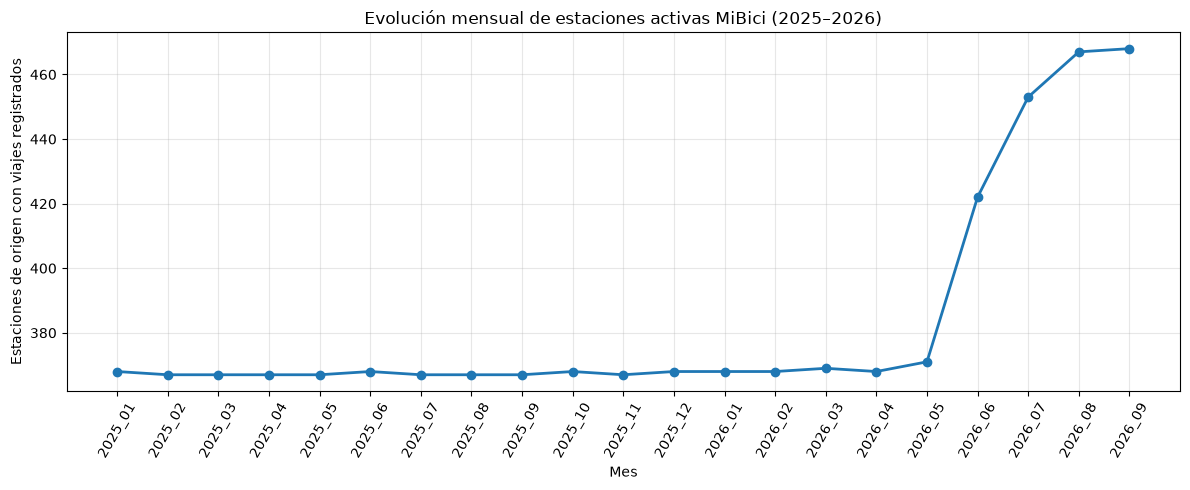

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    estaciones_df["mes"],
    estaciones_df["estaciones_origen_activas"],
    marker="o",
    linewidth=2
)

plt.title("Evolución mensual de estaciones activas MiBici (2025–2026)")
plt.xlabel("Mes")
plt.ylabel("Estaciones de origen con viajes registrados")

plt.xticks(rotation=60)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análisis de estaciones de origen con actividad registrada

Durante 2025 y los primeros meses de 2026, el número de estaciones de origen distintas con viajes registrados se mantuvo relativamente estable, alrededor de 367 a 369 estaciones.

A partir de junio de 2026 se identificó un incremento importante, pasando de 371 estaciones en mayo a 422 en junio, hasta alcanzar 468 en septiembre. Esto representa un aumento aproximado del 26.1 % respecto a mayo de 2026.

En el mismo periodo, el volumen mensual de viajes también aumentó. Sin embargo, el indicador de viajes por estación activa pasó de 851.47 en mayo a 1,045.51 en septiembre, lo que indica que el crecimiento del volumen registrado no se relaciona exclusivamente con el número de estaciones que presentaron actividad.

Es importante señalar que este análisis identifica estaciones con al menos un viaje de origen durante cada mes, pero no permite determinar directamente el número de estaciones oficialmente operativas ni sus fechas exactas de incorporación.

**Implicación para el modelado:** los cambios en el conjunto de estaciones podrían modificar la distribución de los datos y afectar la evaluación de modelos entrenados con periodos anteriores. Se recomienda considerar esta situación al definir los conjuntos de entrenamiento, validación y prueba, así como al analizar posibles cambios de distribución (*data drift*).

## Conclusiones generales del análisis exploratorio y limpieza de datos

El análisis exploratorio y el proceso de limpieza permitieron evaluar la calidad y el comportamiento de los registros históricos de viajes del sistema MiBici, correspondientes al periodo de enero de 2025 a septiembre de 2026.

### 1. Calidad e integridad de los datos

Se analizaron **21 archivos mensuales**, con un total de **7,894,097 registros originales**. Después de eliminar 758 duplicados exactos, identificados en septiembre de 2026, se conservaron **7,893,339 registros**.

Los archivos presentaron una estructura consistente de ocho columnas. Se identificaron valores faltantes principalmente en las variables demográficas `Genero` y `Año_de_nacimiento`, mientras que las columnas necesarias para el análisis temporal y geográfico de los viajes no presentaron valores nulos.

No se identificaron fechas inválidas ni duraciones negativas en los registros analizados.

### 2. Identificación y tratamiento de anomalías

Se identificaron viajes con duraciones menores a un minuto y mayores a tres horas. La proporción de viajes cortos se mantuvo relativamente estable durante 2025, pero presentó incrementos durante 2026, alcanzando un máximo de **4.99 % en junio**.

La mayoría de los viajes cortos registraron la misma estación de origen y destino, aunque también se detectaron viajes de corta duración entre estaciones diferentes.

Como estrategia de limpieza, se decidió eliminar únicamente los duplicados exactos y conservar los viajes con duraciones sospechosas, identificándolos mediante indicadores. Esto permite evaluar posteriormente su impacto sin descartar información de manera anticipada.

### 3. Comportamiento temporal de los viajes

El volumen mensual de viajes presentó variaciones importantes durante el periodo analizado. El menor volumen se registró en mayo de 2026, con **315,895 viajes**, mientras que septiembre de 2026 presentó el máximo, con **489,298 viajes** después de la limpieza.

Al normalizar por el número de días de cada mes, septiembre continuó presentando el mayor promedio diario, con aproximadamente **16,310 viajes**.

El análisis por día de la semana mostró mayor actividad durante los días laborales, especialmente los martes y miércoles, mientras que los domingos registraron el menor promedio de viajes.

Por su parte, la distribución horaria mostró dos picos principales de actividad: **8:00 y 18:00 horas**, siendo este último el de mayor volumen.

Estos resultados sugieren que las variables temporales, como hora y día de la semana, podrían ser relevantes para la predicción de demanda.

### 4. Cambios en las estaciones con actividad registrada

Durante 2025 y los primeros meses de 2026, el número de estaciones de origen con viajes registrados permaneció relativamente estable, alrededor de 367 a 369 estaciones.

A partir de junio de 2026 se observó un incremento importante, pasando de **371 estaciones en mayo a 468 en septiembre**, equivalente a un aumento aproximado del 26.1 %.

Este cambio coincide con el incremento del volumen de viajes y podría influir en la distribución de los datos utilizados para entrenar y evaluar modelos predictivos.

Sin embargo, el número de estaciones con actividad registrada no equivale necesariamente al número de estaciones oficialmente operativas.

### 5. Implicaciones para el proyecto de MLOps

Los resultados obtenidos permiten establecer una base para la preparación del dataset de modelado.

Se implementó una función reutilizable de limpieza en `cleaning.py`, acompañada de pruebas unitarias y validaciones sobre los archivos mensuales.

Como siguientes pasos se recomienda:

- Definir con el equipo la granularidad de la predicción: demanda por estación o por zona y hora.
- Construir las variables temporales necesarias para el modelo.
- Considerar los cambios en las estaciones al definir los periodos de entrenamiento, validación y prueba.
- Evaluar el posible cambio de distribución (*data drift*) entre los periodos anteriores y posteriores a junio de 2026.
- Determinar si los viajes de duración sospechosa deben incluirse en el cálculo de demanda, según la definición final del problema.

En conclusión, el análisis permitió identificar patrones temporales, anomalías y cambios relevantes en los registros de MiBici, así como establecer criterios de limpieza reproducibles para las siguientes etapas del proyecto.